# The Perceptron

## Fundamentos teóricos

Un **perceptrón** es un red neuronal de una sola capa (consta de una sola neurona). Su objetivo principal es clasificar los datos de entrada en una de dos clases (clasificación binaria). Realiza esta clasificación **aprendiendo** un límite de decisión que separa las dos clases.

### Estructura de un perceptrón
Un perceptrón se compone de:
  1. Entradas ($x_1, x_2, …, x_n$): Son las características o atributos de los datos de entrada. Cada entrada está asociada a un peso.
  2. Pesos ($w_1, w_2, …, w_n$): Son parámetros que determinan la importancia de cada entrada. Los pesos se ajustan durante el proceso de entrenamiento.
  3. Sesgo ($b$): El sesgo es un parámetro adicional que permite cambiar el límite de decisión. Ayuda a hacer que el perceptrón sea más flexible.
  4. Función de activación: El perceptrón utiliza una función escalonada (o función escalonada de Heaviside) como función de activación. Esta función produce una salida binaria ($0 o 1$) en función de si la suma ponderada de entradas excede un cierto umbral.
  5. Salida / regla de aprendizaje ($y$): Este es el resultado del cálculo del perceptrón. Representa la clase a la que pertenecen los datos de entrada (hablaremos de la regla de aprendizaje más adelante).

### ¿Cómo funciona el perceptrón?

1. Primero se hace una **suma ponderada**: Calcula la suma ponderada de las entradas más el sesgo (o bias).

$$ z = \sum_{j=1}^{n} w_1x_1 + w_2x_2 +....+ w_j x_j + b $$

2. Después, aplica la **función de activación** a la suma ponderada (predice la clase en funcion a los pesos).

$$ \hat{y} = f(z) = f\left(\sum_{j=1}^{n} w_j x_j + b\right) $$

3. Finalmente, el resultado de la función  de activación ($\hat{y}$) es la salida del perceptrón (o sea la clase predicha), y esta se compara con la "clase original" (regla de aprendizaje) y se decide si ajustar los pesos y/o bias o no.

### Entrenando el perceptrón
Este ejercicio de comparación "clase-predicha / clase-original" que mencionamos, implica ajustar los pesos y el sesgo en función de los errores cometidos durante la clasificación. Este proceso lo llamamos **Algoritmo de aprendizaje del Perceptrón/regla de aprendizaje del Perceptrón**.

  $$ w_j \leftarrow w_j+\eta(y-\hat{y})x_j $$

  $$ b \leftarrow b+\eta(y-\hat{y}) $$

Donde:
- $y$ : clase real.
- $\hat{y}$ : clase predicha.
- $\eta$ : tasa de aprendizaje (learning rate).
- $x_j$ : característica de entrada.

Este proceso conlleva iterar a través de los datos de entrenamiento varias veces hasta que el perceptrón converja y se minimicen los errores de clasificación. Cada iteración se le llama "época".

## Perceptron Pipeline

### El Perceptrón y el Dataset Iris: De Binario a Multiclase

Hasta ahora hemos visto cómo el **Perceptrón** clasifica problemas binarios (Sí/No, Aprobado/Rechazado, 1/0). Pero, ¿qué sucede cuando nos enfrentamos al mundo real y tenemos más de dos categorías?

+ En esta sesión, nos basaremos en el clásico problema botánico de **Edgar Anderson y Ronald Fisher (1936)**.

+ Utilizaremos las dimensiones anatómicas de los pétalos y sépalos de las flores Iris para enseñarle a una neurona a clasificarlas en **3 especies diferentes**: *Setosa, Versicolor y Virginica*.

---
### La Magia Matemática: One-vs-Rest (OvR)
Como el Perceptrón original solo traza un hiperplano (divide el mundo en dos), `Scikit-learn` aplica internamente una estrategia de ingeniería llamada **One-vs-Rest** (Uno contra el Resto) cuando detecta 3 o más clases.

En lugar de entrenar 1 neurona, la librería entrena **3 neuronas simultáneamente**:
1. La neurona A aprende: *¿Es Setosa (1) o No es Setosa (0)?*
2. La neurona B aprende: *¿Es Versicolor (1) o No es Versicolor (0)?*
3. La neurona C aprende: *¿Es Virginica (1) o No es Virginica (0)?*

Al final, se queda con la neurona que tenga mayor "confianza" en su predicción.

In [1]:
# IMPORTACIÓN DE LIBRERÍAS FUNDAMENTALES
import pandas as pd                  # Manipulación y análisis de datos mediante DataFrames.
import numpy as np                   # Operaciones numéricas y manejo de arreglos.
import matplotlib.pyplot as plt      # Creación de gráficas y visualización de datos.

# Módulos de Scikit-learn necesarios para nuestro pipeline
from sklearn.datasets import load_iris             # Carga el conjunto de datos Iris.
from sklearn.model_selection import train_test_split  # Divide los datos en entrenamiento y prueba.
from sklearn.preprocessing import StandardScaler   # Estandariza las características de entrada para que las diferencias entre clases no sean impedimento para clasificar.
from sklearn.linear_model import Perceptron         # Implementa el modelo de clasificación Perceptrón.
from sklearn.metrics import accuracy_score          # Calcula la exactitud de las predicciones.

### 1. Extracción y Comprensión del Dataset (Data Ingestion)

El dataset Iris viene incorporado directamente en `sklearn.datasets`. Contiene 150 muestras (50 de cada especie). Cada muestra tiene 4 características numéricas (en centímetros): longitud y ancho del sépalo, y longitud y ancho del pétalo.

In [2]:
# Cargamos el dataset desde la librería
iris = load_iris()

# Extraemos nuestras variables predictoras (X) y nuestro objetivo (y)
X = iris.data
y = iris.target # 0: Setosa, 1: Versicolor, 2: Virginica

# Para hacerlo visual, lo convertimos a un DataFrame de Pandas
df_iris = pd.DataFrame(X, columns=iris.feature_names)
df_iris['Especie'] = y

print("--- Dimensiones de la Matriz del Dataset ---")
print(f"Filas (Muestras): {df_iris.shape[0]}, Columnas (Características + Etiqueta): {df_iris.shape[1]}\n")

print("--- Vistazo a los datos crudos ---")
display(df_iris.head())

--- Dimensiones de la Matriz del Dataset ---
Filas (Muestras): 150, Columnas (Características + Etiqueta): 5

--- Vistazo a los datos crudos ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Especie
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### 2. Preparación de los Datos (Split & Scale)

El Perceptrón es un modelo basado en el cálculo de distancias (producto punto de vectores). Si no **estandarizamos** las características, aquellas con números más grandes dominarán artificialmente el entrenamiento. Aplicaremos la fórmula de estandarización normal (Z-score):

$$z = \frac{x - \mu}{\sigma}$$

In [4]:
# 1. DIVISIÓN DEL DATASET (Train/Test Split)
# Divide los datos en 80% para entrenamiento y 20% para prueba.
# stratify=y mantiene la proporción de las tres clases en ambos conjuntos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 2. ESCALADO DE CARACTERÍSTICAS (Standardization)
scaler = StandardScaler()  # Inicializa el estandarizador. (StandardScaler utiliza la desviación estándar poblacional (ddof=0))

# Calcula la media y la desviación estándar del conjunto de entrenamiento
# y utiliza esos valores para estandarizar sus características.
X_train_scaled = scaler.fit_transform(X_train)
print(X_train_scaled)

# Estandariza los datos de prueba usando la media y desviación estándar
# calculadas previamente con los datos de entrenamiento.
X_test_scaled = scaler.transform(X_test)

print("--- Datos divididos y estandarizados correctamente ---")

[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]
 [ 0.54731923 -1.22765467  0.69841284  0.91510102]
 [-0.2885865  -0.77987789  0.24416059  0.12508575]
 [ 0.54731923 -0.5559895   0.75519438  0.38842418]
 [ 2.21913069 -0.10821272  1.3230097   1.44177787]
 [ 2.21913069  1.6828944   1.66369889  1.31010866]
 [ 2.09971558 -0.10821272  1.60691736  1.17843945]
 [ 0.18907392 -0.33210111  0.41450518  0.38842418]
 [-1.00507713 -2.34709662 -0.15331014 -0.26992188]
 [-0.04975629 -0.77987789  0.18737906 -0.26992188]
 [-0.04975629 -1.00376628  0.13059752 -0.00658346]
 [-1.36332244  0.33956406 -1.23215924 -1.32327558]
 [-0.88566202  1.6828944  -1.28894078 -1.19160637]
 [ 1.02497964 -1.22765467  1.1526651   0.78343181]
 [ 0.66673433  0.11567567  0.9823205   0.78343181]
 [-0.52741671  0.78734084 -1.28

### Importancia de la estandarización de los datos

La estandarización transforma las características para que sean comparables y evita que las diferencias de escala afecten excesivamente al aprendizaje del Perceptrón.

#### Diferencia entre fit_transform() y transform()

- **fit_transform(X_train)**: calcula la media y la desviación estándar de cada característica del conjunto de entrenamiento (fit) y aplica la estandarización (transform).
- **transform(X_test)**: estandariza los datos de prueba utilizando los parámetros calculados con el conjunto de entrenamiento.

**Regla fundamental:** no se debe ajustar (fit) el escalador con los datos de prueba, porque introduciría información de ese conjunto en el proceso de preparación, provocando una posible fuga de datos (*Data Leakage*).

### 3. Entrenamiento del Algoritmo (Training)

Instanciamos nuestro modelo. Scikit-learn detectará automáticamente que el vector `y` tiene 3 clases únicas y aplicará la estrategia Multiclase (One-vs-Rest) sin que tengamos que escribir código adicional.

In [5]:
# Instanciamos la clase Perceptron
modelo_per = Perceptron(
    max_iter=1000,    # Máximo número de épocas
    eta0=0.1,         # Tasa de aprendizaje (qué tan grandes son los pasos al ajustar pesos)
    random_state=42,  # Semilla para barajar los datos (dejarlo como constante: no cambiar siempre)
    n_jobs=-1         # Permite a scikit-learn usar todos los núcleos del CPU para entrenar más rápido
)

# Comenzamos la optimización de pesos sinápticos
modelo_per.fit(X_train_scaled, y_train)

print(f"Modelo entrenado. Convergió en {modelo_per.n_iter_} épocas.")

Modelo entrenado. Convergió en 8 épocas.


## 4. Gráficación de los datos (scatter)

Gráfico de dispersión de los datos de entrenamiento + predicciones (parte del dataset que dividimos como datos de prueba para la comparación) y frontera de decisión.

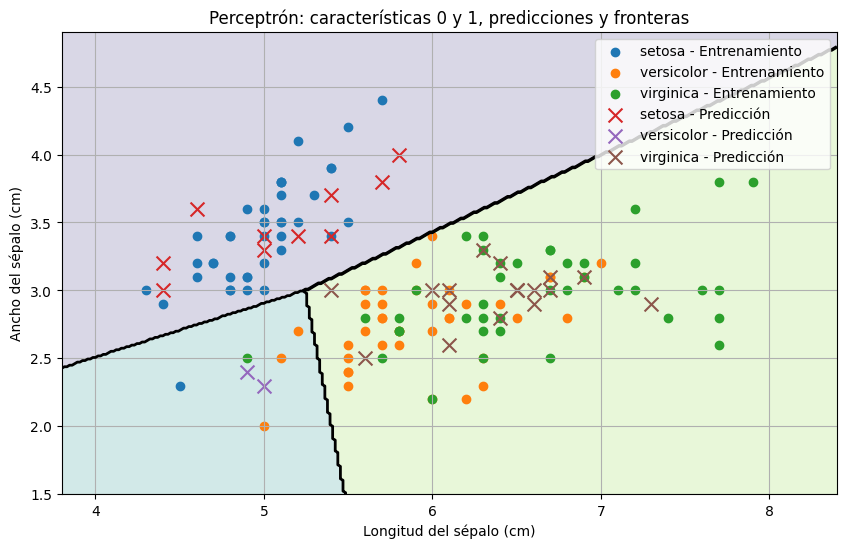

In [19]:
# 1. Seleccionar las características 0 y 1
X_2 = X[:, [0, 1]]  # Longitud y ancho del sépalo

# 2. DIVIDIR LOS DATOS
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_2, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. ESCALAR LAS DOS CARACTERÍSTICAS
scaler_2 = StandardScaler()
X_train_2_scaled = scaler_2.fit_transform(X_train_2)
X_test_2_scaled = scaler_2.transform(X_test_2)

# 4. ENTRENAR UN PERCEPTRÓN CON LAS DOS CARACTERÍSTICAS
modelo_per_2 = Perceptron(
    max_iter=1000,
    eta0=0.1,
    random_state=42
)
modelo_per_2.fit(X_train_2_scaled, y_train_2)

# 5. PREDECIR LAS CLASES DE LOS DATOS DE PRUEBA
y_pred_2 = modelo_per_2.predict(X_test_2_scaled)

# 6. CREAR LA MALLA PARA LA FRONTERA DE DECISIÓN
x_min, x_max = X_train_2[:, 0].min() - 0.5, X_train_2[:, 0].max() + 0.5
y_min, y_max = X_train_2[:, 1].min() - 0.5, X_train_2[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Transformar los puntos de la malla con el mismo escalador
malla = np.c_[xx.ravel(), yy.ravel()]
malla_scaled = scaler_2.transform(malla)

# Predecir la clase de cada punto de la malla
Z = modelo_per_2.predict(malla_scaled).reshape(xx.shape)

# 7. GRAFICAR LAS REGIONES DE DECISIÓN
plt.figure(figsize=(10, 6))
plt.contourf(
    xx, yy, Z,
    alpha=0.2,
    levels=[-0.5, 0.5, 1.5, 2.5]
)

# Graficar los datos de entrenamiento por especie
for clase, nombre in enumerate(iris.target_names):
    plt.scatter(
        X_train_2[y_train_2 == clase, 0],
        X_train_2[y_train_2 == clase, 1],
        label=f"{nombre} - Entrenamiento"
    )

# Graficar los datos de prueba según la clase predicha
for clase, nombre in enumerate(iris.target_names):
    indices = y_pred_2 == clase

    plt.scatter(
        X_test_2[indices, 0],
        X_test_2[indices, 1],
        marker="x",
        s=100,
        label=f"{nombre} - Predicción"
    )

# Dibujar las fronteras entre las regiones de las tres clases
plt.contour(
    xx, yy, Z,
    levels=[0.5, 1.5],
    colors="black",
    linewidths=2
)

# Configurar la gráfica
plt.xlabel("Longitud del sépalo (cm)")
plt.ylabel("Ancho del sépalo (cm)")
plt.title("Perceptrón: características 0 y 1, predicciones y fronteras")
plt.legend()
plt.grid(True)
plt.show()

## 5. Evaluación del Modelo (Scoring)

Es momento de ver cómo se comporta nuestro modelo ante datos que nunca ha visto (el 20% que reservamos en `X_test`).

In [20]:
# 1. INFERENCIA: predice las clases de los datos de prueba.
y_pred = modelo_per.predict(X_test_scaled)

# 2. EVALUACIÓN: calcula la proporción de predicciones correctas.
exactitud_global = accuracy_score(y_test, y_pred)
print(f"Exactitud (Accuracy) del modelo: {exactitud_global * 100:.2f}%\n")

Exactitud (Accuracy) del modelo: 86.67%



### La Métrica de Exactitud (*Accuracy*)
La métrica más intuitiva para evaluar un clasificador como el Perceptrón es la **Exactitud** (*Accuracy*), la cual mide globalmente la proporción de predicciones correctas sobre el total de evaluaciones.

El Accuracy se expresa como:
$
\text{Accuracy}=\frac{\text{Predicciones correctas}}{\text{Total de predicciones}}
$

o sea:

$
\text{Accuracy}=\frac{1}{n}\sum_{i=1}^{n} \mathbb{I}(y_i=\hat{y}_i)
$

Donde:
* $\mathbb{I}(y_i=\hat{y}_i)$: vale 1 si la predicción es correcta y 0 si es incorrecta.

### Matriz de Confusión

La exactitud (Accuracy) también puede calcularse mediante la matriz de confusión, que permite distinguir los aciertos y errores del modelo:

$$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$

* TP (Verdaderos positivos): predijo positivo y era positivo.
* TN (Verdaderos negativos): predijo negativo y era negativo.
* FP (Falsos positivos): predijo positivo, pero era negativo.
* FN (Falsos negativos): predijo negativo, pero era positivo.

### ¿Por qué usar la matriz de confusión si ya tenemos la fórmula de exactitud?

El Accuracy solo indica qué proporción de predicciones fueron correctas. La matriz de confusión permite identificar qué tipos de errores comete el modelo y calcular otras métricas, como **Precision** y ***Recall***.

⚠️ Precaución (**Paradoja de la Exactitud**)⚠️: si el dataset está desbalanceado, el Accuracy puede ser engañoso. Por ejemplo, si el 99 % de las transacciones son legítimas y el modelo clasifica todas como legítimas, obtendría un 99 % de exactitud, pero no detectaría ningún fraude. Por eso conviene complementarlo con otras métricas.

Dataset "desbalanceado": las clases tienen cantidades muy diferentes de observaciones (Problema al aprender a clasificar: "más casos de la clase A, que de B"; B no se aprende)